In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf

I0000 00:00:1791868280.881637    1510 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791868306.807750    1510 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
import numpy as np
import tensorflow as tf

from tensorflow.keras.layers import Input, Layer, Dense, Add
from tensorflow.keras.layers import Activation, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras import optimizers
from tensorflow.keras.preprocessing.text import Tokenizer
from nltk.util import ngrams
import matplotlib.pyplot as plt


In [4]:
sentences = [ 
    "the cat is walking in the bedroom",
    "a dog was running in a room",
    "the cat is running in a room",
    "a dog is walking in a bedroom",
    "the dog was walking in the room"
]

In [5]:
# Data preprocessing
tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)
word2idx = tokenizer.word_index
idx2word = { v:k for (k,v) in word2idx.items()}
sequences = tokenizer.texts_to_sequences(sentences)

In [6]:
print(word2idx)
print(idx2word)
print(sequences)

{'the': 1, 'in': 2, 'a': 3, 'is': 4, 'walking': 5, 'dog': 6, 'room': 7, 'cat': 8, 'bedroom': 9, 'was': 10, 'running': 11}
{1: 'the', 2: 'in', 3: 'a', 4: 'is', 5: 'walking', 6: 'dog', 7: 'room', 8: 'cat', 9: 'bedroom', 10: 'was', 11: 'running'}
[[1, 8, 4, 5, 2, 1, 9], [3, 6, 10, 11, 2, 3, 7], [1, 8, 4, 11, 2, 3, 7], [3, 6, 4, 5, 2, 3, 9], [1, 6, 10, 5, 2, 1, 7]]


In [7]:
n=4 #4 n-grams
list_ngrams = [list(ngrams(s, n)) for s in sequences]
array_ngrams = np.array(list_ngrams).reshape(-1,n)

print(list_ngrams)
print(array_ngrams)

[[(1, 8, 4, 5), (8, 4, 5, 2), (4, 5, 2, 1), (5, 2, 1, 9)], [(3, 6, 10, 11), (6, 10, 11, 2), (10, 11, 2, 3), (11, 2, 3, 7)], [(1, 8, 4, 11), (8, 4, 11, 2), (4, 11, 2, 3), (11, 2, 3, 7)], [(3, 6, 4, 5), (6, 4, 5, 2), (4, 5, 2, 3), (5, 2, 3, 9)], [(1, 6, 10, 5), (6, 10, 5, 2), (10, 5, 2, 1), (5, 2, 1, 7)]]
[[ 1  8  4  5]
 [ 8  4  5  2]
 [ 4  5  2  1]
 [ 5  2  1  9]
 [ 3  6 10 11]
 [ 6 10 11  2]
 [10 11  2  3]
 [11  2  3  7]
 [ 1  8  4 11]
 [ 8  4 11  2]
 [ 4 11  2  3]
 [11  2  3  7]
 [ 3  6  4  5]
 [ 6  4  5  2]
 [ 4  5  2  3]
 [ 5  2  3  9]
 [ 1  6 10  5]
 [ 6 10  5  2]
 [10  5  2  1]
 [ 5  2  1  7]]


In [8]:
# training data
x_train = array_ngrams[:, :-1]
y_train = array_ngrams[:, -1]

In [ ]:
m = 8                   # word embedding size vector
V = len(word2idx) + 1   # vocabulary size
# h = 64                  # no. of hidden units           <<<<<========= change here
r=64

In [20]:
# word embedding layer
class WordEmbedding(Layer):
    def __init__(self, input_dim, emb_size, name=None):
        super(WordEmbedding, self).__init__(name=name)

        # Matrix C registered as a Keras layer weight
        self.C = self.add_weight(
            name='C',
            shape=(input_dim, emb_size),
            initializer='random_normal',
            trainable=True
        )

    def call(self, x):
        # Table look up in C
        selected_rows = tf.gather(self.C, x) # (None, 3, 8)
        return selected_rows
        

In [ ]:
# create NPLM model
x_input = Input(batch_shape = (None, x_train.shape[1]), dtype='int32')
x_embed = Embedding(V, m, name='emb')(x_input)          #(None,3,8)
x_concat = Flatten()(x_embed)
Hx = Dense(h, activation='tanh')(x_concat)
Wx = Dense(V, use_bias = False)(x_concat)
Ux = Dense(V)(Hx)
y = Add()([Wx, Ux])
y_prob = Activation('softmax')(y)

In [23]:
model = Model(x_input, y_prob)
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=optimizers.Adam(learning_rate=0.01)
)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb (WordEmbedding) │ (None, 3, 8)      │         96 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 24)        │          0 │ emb[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      1,600 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 12)        │        288 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 12)        │        780 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 12)        │          0 │ dense_4[0][0],    │
│                     │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 12)        │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,764 (10.80 KB)

 Trainable params: 2,764 (10.80 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# fit data to the model
hist = model.fit(x_train, y_train, epochs=100)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 681ms/step - loss: 2.4645
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 2.3250
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 2.1791
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 2.0133
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 1.8213
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 1.6048
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 1.3728
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 1.1414
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.9293
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.7528
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.6202
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.5292
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.4696
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.4307
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.4063
Epoch 16/100
1/1 ━

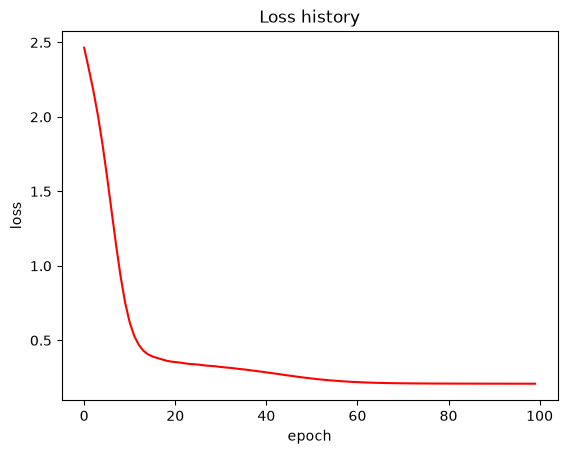

In [25]:
# losss history
plt.plot(hist.history['loss'], color='red')
plt.title("Loss history")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

In [26]:
# matrix C
C = model.get_layer('emb').get_weights()[0]

In [27]:
# word vector
print("\nWord vectors:")
for word, idx in word2idx.items():
    word_vector = C[idx, :]
    print("{:10s}".format(word), end='')
    print(word_vector.round(3))


Word vectors:
the       [-0.448  0.128  0.45   0.265 -0.216 -0.388  0.541 -0.387]
in        [ 0.355  0.488 -0.369  0.297  0.143 -0.297 -0.601 -0.557]
a         [ 0.113  0.021  0.215  0.351 -0.641 -0.281  0.056 -0.26 ]
is        [ 0.419 -0.092 -0.202 -0.553 -0.261  0.641 -0.313  0.106]
walking   [-0.368  0.177 -0.317 -0.472  0.535 -0.409  0.435 -0.217]
dog       [-0.662 -0.127 -0.603 -0.066 -0.124 -0.328  0.105  0.276]
room      [-0.001  0.01  -0.026 -0.002  0.001  0.001  0.004  0.046]
cat       [-0.24  -0.414 -0.192 -0.286 -0.481 -0.008 -0.185  0.432]
bedroom   [-0.041 -0.044  0.005 -0.085 -0.046  0.067  0.033 -0.004]
was       [ 0.406 -0.354  0.241 -0.434  0.097  0.262  0.08  -0.012]
running   [ 0.148  0.354  0.33   0.356  0.186  0.024  0.033 -0.69 ]


In [28]:
# P(w4 | w1, w2, w3)
print("\nP(w4 | w1, w2, w3):")
x = x_train[0] #"the", "cat", "is"
p = model.predict(
    x.reshape(1, -1),
    verbose=0
)[0]

print(idx2word[x[0]],idx2word[x[1]],idx2word[x[2]], ':')

for word, idx in word2idx.items():
    print("{:10s}: {:.3f}".format(word, p[idx]))


P(w4 | w1, w2, w3):
the cat is :
the       : 0.000
in        : 0.000
a         : 0.000
is        : 0.000
walking   : 0.502
dog       : 0.000
room      : 0.000
cat       : 0.000
bedroom   : 0.000
was       : 0.000
running   : 0.498


In [30]:
# sentence matrix
print("\n sentence matrix:")
i=0
print('sen:', sentences[i], ':')
print(C[sequences[i]].round(2))


 sentence matrix:
sen: the cat is walking in the bedroom :
[[-0.45  0.13  0.45  0.26 -0.22 -0.39  0.54 -0.39]
 [-0.24 -0.41 -0.19 -0.29 -0.48 -0.01 -0.18  0.43]
 [ 0.42 -0.09 -0.2  -0.55 -0.26  0.64 -0.31  0.11]
 [-0.37  0.18 -0.32 -0.47  0.53 -0.41  0.43 -0.22]
 [ 0.35  0.49 -0.37  0.3   0.14 -0.3  -0.6  -0.56]
 [-0.45  0.13  0.45  0.26 -0.22 -0.39  0.54 -0.39]
 [-0.04 -0.04  0.01 -0.08 -0.05  0.07  0.03 -0.  ]]
